# Figure 2 Generation

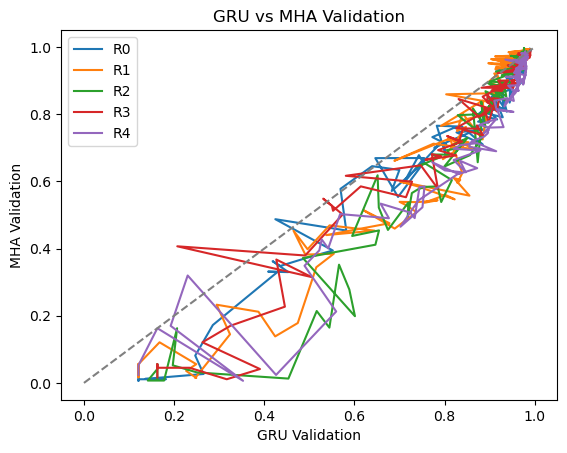

In [1]:
import wandb
import numpy as np
import matplotlib.pyplot as plt

api = wandb.Api()

# Replace with your project, run ID
def load_vec(run_key):
    run = api.run(run_key) 
    history = run.history() 
    vec = history['epoch/val_sparse_categorical_accuracy']
    vec = vec[~np.isnan(vec)]
    return vec

def pad(gru_vec, mha_vec):
    if len(gru_vec) > len(mha_vec):
        mha_vec.extend([mha_vec[-1]] * (len(gru_vec) - len(mha_vec)))
    if len(mha_vec) > len(gru_vec):
        gru_vec.extend([gru_vec[-1]] * (len(mha_vec) - len(gru_vec)))
    return gru_vec, mha_vec

# -2 Series (Example: GRU-2_R0)
gru_R0 = load_vec("addalooptoit-me/HW6/ifsph9la")
mha_R0 = load_vec("addalooptoit-me/HW6/8djsoahs")
gru_R0, mha_R0 = pad(list(gru_R0), list(mha_R0))

gru_R1 = load_vec("addalooptoit-me/HW6/q8s8mtxg")
mha_R1 = load_vec("addalooptoit-me/HW6/qgkm13g6")
gru_R1, mha_R1 = pad(list(gru_R1), list(mha_R1))

gru_R2 = load_vec("addalooptoit-me/HW6/e2oqrmga")
mha_R2 = load_vec("addalooptoit-me/HW6/shy6ph9s")
gru_R2, mha_R2 = pad(list(gru_R2), list(mha_R2))

gru_R3 = load_vec("addalooptoit-me/HW6/ieo8lnkb")
mha_R3 = load_vec("addalooptoit-me/HW6/ewcya6y5")
gru_R3, mha_R3 = pad(list(gru_R3), list(mha_R3))

gru_R4 = load_vec("addalooptoit-me/HW6/2mcrnkxc")
mha_R4 = load_vec("addalooptoit-me/HW6/qzt8isoz")
gru_R4, mha_R4 = pad(list(gru_R4), list(mha_R4))

plt.plot(gru_R0, mha_R0, label='R0')
plt.plot(gru_R1, mha_R1, label='R1')
plt.plot(gru_R2, mha_R2, label='R2')
plt.plot(gru_R3, mha_R3, label='R3')
plt.plot(gru_R4, mha_R4, label='R4')

x = np.linspace(0, 1, 100)
y = x
plt.plot(x, y, linestyle='--', color='gray')

plt.title('GRU vs MHA Validation')
plt.xlabel('GRU Validation')
plt.ylabel('MHA Validation')
plt.legend()
plt.savefig('fig2.png')
plt.show()


# Figure 3 Generation

rnn rotation: 0 | rnn test acc: 0.9816882610321044
gru rotation: 0 | gru test acc: 0.9892926812171936
mha rotation: 0 | mha test acc: 0.9943792819976808
rnn rotation: 1 | rnn test acc: 0.971567928791046
gru rotation: 1 | gru test acc: 0.9897095561027528
mha rotation: 1 | mha test acc: 0.9908783435821532
rnn rotation: 2 | rnn test acc: 0.984953999519348
gru rotation: 2 | gru test acc: 0.9806079268455504
mha rotation: 2 | mha test acc: 0.9970517754554749
rnn rotation: 3 | rnn test acc: 0.9721643328666688
gru rotation: 3 | gru test acc: 0.9879251718521118
mha rotation: 3 | mha test acc: 0.9877471923828124
rnn rotation: 4 | rnn test acc: 0.6654630303382874
gru rotation: 4 | gru test acc: 0.9818440675735474
mha rotation: 4 | mha test acc: 0.983522355556488


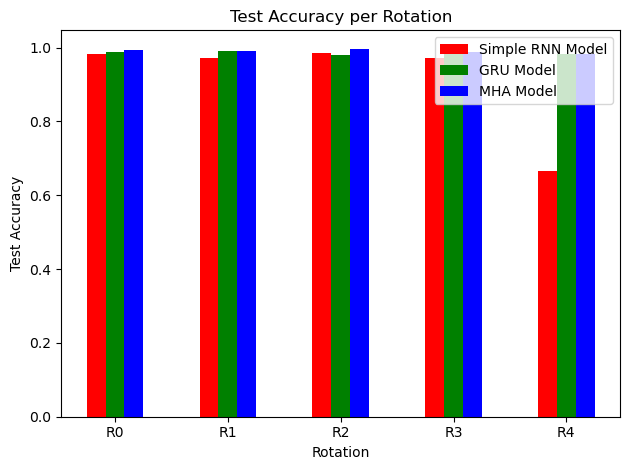

In [7]:
#run.config
def get_test_acc(run_key):
    run = api.run(run_key) 
    return run.summary['final_test_sparse_categorical_accuracy']


run = api.run("addalooptoit-me/HW6/ifsph9la") 
#mha_R0 = load_vec("addalooptoit-me/HW6/8djsoahs")

rotations = ['R0', 'R1', 'R2', 'R3', 'R4']

# Bar width and positions
bar_width = 0.25
x = np.arange(len(rotations)) * 1.5

rnn_test = []
gru_test = []
mha_test = []


rnn_test.append(get_test_acc("addalooptoit-me/HW6/sc1f0h8x"))
gru_test.append(get_test_acc("addalooptoit-me/HW6/ifsph9la"))
mha_test.append(get_test_acc("addalooptoit-me/HW6/8djsoahs"))

rnn_test.append(get_test_acc("addalooptoit-me/HW6/fs84y62f"))
gru_test.append(get_test_acc("addalooptoit-me/HW6/q8s8mtxg"))
mha_test.append(get_test_acc("addalooptoit-me/HW6/qgkm13g6"))

rnn_test.append(get_test_acc("addalooptoit-me/HW6/mie4t4t1"))
gru_test.append(get_test_acc("addalooptoit-me/HW6/e2oqrmga"))
mha_test.append(get_test_acc("addalooptoit-me/HW6/shy6ph9s"))

rnn_test.append(get_test_acc("addalooptoit-me/HW6/m9utgjke"))
gru_test.append(get_test_acc("addalooptoit-me/HW6/ieo8lnkb"))
mha_test.append(get_test_acc("addalooptoit-me/HW6/ewcya6y5"))

rnn_test.append(get_test_acc("addalooptoit-me/HW6/zmvtdtk5"))
gru_test.append(get_test_acc("addalooptoit-me/HW6/2mcrnkxc"))
mha_test.append(get_test_acc("addalooptoit-me/HW6/qzt8isoz"))


for i in range(5):
    print('rnn rotation:', i, '| rnn test acc:', rnn_test[i])
    print('gru rotation:', i, '| gru test acc:', gru_test[i])
    print('mha rotation:', i, '| mha test acc:', mha_test[i])
    print('=================================================')



# Plot
plt.bar(x - bar_width, rnn_test, width=bar_width, color="red", label='Simple RNN Model')
plt.bar(x, gru_test, width=bar_width, color="green", label='GRU Model')
plt.bar(x + bar_width, mha_test, width=bar_width, color="blue", label='MHA Model')

# Labels
plt.xlabel('Rotation')
plt.ylabel('Test Accuracy')
plt.title('Test Accuracy per Rotation')
plt.xticks(x, rotations)
plt.legend()
plt.tight_layout()
plt.savefig('fig3.png')
plt.show()
